In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt # for visualization
import seaborn as sns

In [2]:
df=pd.read_csv(r"C:\Users\Owner\Desktop\대학\cct S1\machine learning\CA1\Diabetes Dataset.csv")
#df=pd.read_Csv("Diabetes Dataset.csv")

In [3]:
df.head()

,Gender,Age,Physical Activity,Smoking Status,Alcohol Intake,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function,Family History,Hypertension,Outcome
0,Male,63,Moderate,Former,NaN,103,40,7,41,28.196216,167,1.393,Yes,Yes,Diabetic
1,Female,51,Moderate,Never,Regular,104,59,21,51,30.438114,209,0.815,No,No,Diabetic
2,Female,74,Moderate,Current,NaN,128,70,18,199,38.700428,170,0.244,No,No,Diabetic
3,Male,78,Low,Never,Occasional,148,72,15,110,44.861600,170,0.336,No,No,Diabetic
4,Male,32,High,Never,NaN,102,55,18,49,21.591572,211,1.146,Yes,No,Non-diabetic


In [4]:
df.shape # 20000 rows and 15 columns

(20000, 15)

In [5]:
df.info() # total 7 strings and 8 numerical variables

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Gender                      20000 non-null  str    
 1   Age                         20000 non-null  int64  
 2   Physical Activity           20000 non-null  str    
 3   Smoking Status              20000 non-null  str    
 4   Alcohol Intake              10075 non-null  str    
 5   Glucose                     20000 non-null  int64  
 6   Blood Pressure              20000 non-null  int64  
 7   Skin Thickness              20000 non-null  int64  
 8   Insulin                     20000 non-null  int64  
 9   BMI                         20000 non-null  float64
 10  Cholesterol                 20000 non-null  int64  
 11  Diabetes Pedigree Function  20000 non-null  float64
 12  Family History              20000 non-null  str    
 13  Hypertension                20000 non-null

In [6]:
df.describe() # numerical variables' descriptive statistics

,Age,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,49.565400,119.603400,69.432850,20.105450,83.952550,32.008980,189.555400,1.310665
std,17.320956,29.590699,12.016115,9.130969,53.026841,6.913271,35.081701,0.693984
min,20.000000,40.000000,30.000000,7.000000,15.000000,15.000000,100.000000,0.100000
25%,35.000000,99.000000,61.000000,13.000000,40.000000,27.314424,166.000000,0.704750
50%,50.000000,120.000000,69.000000,20.000000,79.000000,31.994040,190.000000,1.316000
75%,64.000000,140.000000,78.000000,26.000000,120.000000,36.750196,213.000000,1.914000
max,79.000000,200.000000,114.000000,57.000000,276.000000,50.000000,320.000000,2.500000


In [7]:
df.describe(include='str') # categorical variables' descriptive statistics

,Gender,Physical Activity,Smoking Status,Alcohol Intake,Family History,Hypertension,Outcome
count,20000,20000,20000,10075,20000,20000,20000
unique,2,3,3,2,2,2,2
top,Male,Moderate,Never,Occasional,No,No,Diabetic
freq,10028,9976,11999,6014,12083,13974,16726


In [8]:
df.isnull().sum() # 9925 missing values in 'Alcohol Intake' column

Gender                           0
Age                              0
Physical Activity                0
Smoking Status                   0
Alcohol Intake                9925
Glucose                          0
Blood Pressure                   0
Skin Thickness                   0
Insulin                          0
BMI                              0
Cholesterol                      0
Diabetes Pedigree Function       0
Family History                   0
Hypertension                     0
Outcome                          0
dtype: int64

In [9]:
df['Alcohol Intake'].unique() # dataset's 'none' detected as nan automatically in python circumstance -> change it to a real 'None' value


<StringArray>
[nan, 'Regular', 'Occasional']
Length: 3, dtype: str

In [10]:
df['Alcohol Intake'].head()

0           NaN
1       Regular
2           NaN
3    Occasional
4           NaN
Name: Alcohol Intake, dtype: str

In [11]:
df['Alcohol Intake']= df['Alcohol Intake'].fillna('None') #-> change it to a real 'None' value with fillna funcion


In [12]:
df['Alcohol Intake'].head() # number 0,2,4 is changed from nan to None

0          None
1       Regular
2          None
3    Occasional
4          None
Name: Alcohol Intake, dtype: str

In [13]:
df['Alcohol Intake'].info() 

<class 'pandas.Series'>
RangeIndex: 20000 entries, 0 to 19999
Series name: Alcohol Intake
Non-Null Count  Dtype
--------------  -----
20000 non-null  str  
dtypes: str(1)
memory usage: 156.4 KB


In [14]:
df.isnull().sum() # there is no more missing values in a dataset 

Gender                        0
Age                           0
Physical Activity             0
Smoking Status                0
Alcohol Intake                0
Glucose                       0
Blood Pressure                0
Skin Thickness                0
Insulin                       0
BMI                           0
Cholesterol                   0
Diabetes Pedigree Function    0
Family History                0
Hypertension                  0
Outcome                       0
dtype: int64

# preprocessing


In [15]:
# make all the categorical variables as numbers to use for machine learning
#mapping

print(df['Physical Activity'].unique())
print(df['Physical Activity'].value_counts())


<StringArray>
['Moderate', 'Low', 'High']
Length: 3, dtype: str
Physical Activity
Moderate    9976
Low         5995
High        4029
Name: count, dtype: int64


In [16]:

df['Physical Activity']=df['Physical Activity'].map({'Moderate':1, 'Low':0, 'High':2})
print(df['Physical Activity'].value_counts())

Physical Activity
1    9976
0    5995
2    4029
Name: count, dtype: int64


In [17]:
print(df['Smoking Status'].unique())
print(df['Smoking Status'].value_counts())


<StringArray>
['Former', 'Never', 'Current']
Length: 3, dtype: str
Smoking Status
Never      11999
Former      4968
Current     3033
Name: count, dtype: int64


In [18]:
#df['Smoking Status']=oe.fit_transform(df[['Smoking Status']])
df['Smoking Status']=df['Smoking Status'].map({'Former':1, 'Never':0, 'Current':2})
print(df['Smoking Status'].value_counts())

Smoking Status
0    11999
1     4968
2     3033
Name: count, dtype: int64


In [19]:
print(df['Alcohol Intake'].unique())
print(df['Alcohol Intake'].value_counts())

<StringArray>
['None', 'Regular', 'Occasional']
Length: 3, dtype: str
Alcohol Intake
None          9925
Occasional    6014
Regular       4061
Name: count, dtype: int64


In [20]:
#df['Alcohol Intake']=oe.fit_transform(df[['Alcohol Intake']])
df['Alcohol Intake']=df['Alcohol Intake'].map({'Occasional':1, 'None':0, 'Regular':2})
print(df['Alcohol Intake'].value_counts())

Alcohol Intake
0    9925
1    6014
2    4061
Name: count, dtype: int64


In [21]:
print(df['Gender'].unique())
print(df['Gender'].value_counts())

<StringArray>
['Male', 'Female']
Length: 2, dtype: str
Gender
Male      10028
Female     9972
Name: count, dtype: int64


In [22]:
#df1=pd.get_dummies(df1, columns=['Gender'], rfype=int)
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})

In [23]:
print(df['Family History'].unique())
print(df['Family History'].value_counts())

<StringArray>
['Yes', 'No']
Length: 2, dtype: str
Family History
No     12083
Yes     7917
Name: count, dtype: int64


In [24]:
df['Family History']=df['Family History'].map({'No':0,'Yes':1})

In [25]:
print(df['Family History'].unique())
print(df['Family History'].value_counts())

[1 0]
Family History
0    12083
1     7917
Name: count, dtype: int64


In [26]:
print(df['Hypertension'].unique())
print(df['Hypertension'].value_counts())

<StringArray>
['Yes', 'No']
Length: 2, dtype: str
Hypertension
No     13974
Yes     6026
Name: count, dtype: int64


In [27]:
df['Hypertension']=df['Hypertension'].map({'Yes':1, 'No':0})

In [28]:
print(df['Hypertension'].unique())
print(df['Hypertension'].value_counts())

[1 0]
Hypertension
0    13974
1     6026
Name: count, dtype: int64


In [29]:
print(df['Outcome'].unique())
print(df['Outcome'].value_counts())

<StringArray>
['Diabetic', 'Non-diabetic']
Length: 2, dtype: str
Outcome
Diabetic        16726
Non-diabetic     3274
Name: count, dtype: int64


In [30]:
df['Outcome']=df['Outcome'].map({'Diabetic':1,"Non-diabetic":0})

In [31]:
print(df['Outcome'].unique())
print(df['Outcome'].value_counts())

[1 0]
Outcome
1    16726
0     3274
Name: count, dtype: int64


In [32]:
df.head()
#there is no more letter in a dataset 

,Gender,Age,Physical Activity,Smoking Status,Alcohol Intake,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function,Family History,Hypertension,Outcome
0,0,63,1,1,0,103,40,7,41,28.196216,167,1.393,1,1,1
1,1,51,1,0,2,104,59,21,51,30.438114,209,0.815,0,0,1
2,1,74,1,2,0,128,70,18,199,38.700428,170,0.244,0,0,1
3,0,78,0,0,1,148,72,15,110,44.861600,170,0.336,0,0,1
4,0,32,2,0,0,102,55,18,49,21.591572,211,1.146,1,0,0


In [33]:
df.shape

(20000, 15)

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Gender                      20000 non-null  int64  
 1   Age                         20000 non-null  int64  
 2   Physical Activity           20000 non-null  int64  
 3   Smoking Status              20000 non-null  int64  
 4   Alcohol Intake              20000 non-null  int64  
 5   Glucose                     20000 non-null  int64  
 6   Blood Pressure              20000 non-null  int64  
 7   Skin Thickness              20000 non-null  int64  
 8   Insulin                     20000 non-null  int64  
 9   BMI                         20000 non-null  float64
 10  Cholesterol                 20000 non-null  int64  
 11  Diabetes Pedigree Function  20000 non-null  float64
 12  Family History              20000 non-null  int64  
 13  Hypertension                20000 non-null

"In this study, the target variable 'Outcome' was encoded as binary classes, where 'Non-diabetic' is represented by 0 and 'Diabetic' is represented by 1."

<Axes: xlabel='Outcome', ylabel='count'>

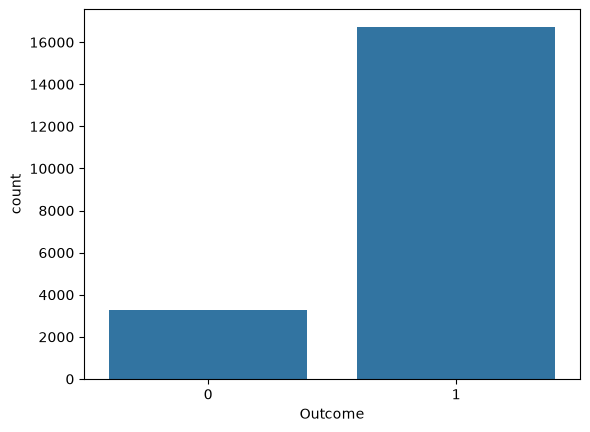

In [35]:
sns.countplot(data=df,x='Outcome')
# 1(diabetic) : over 16000
# 2(Non-diabetic) : less than 4000

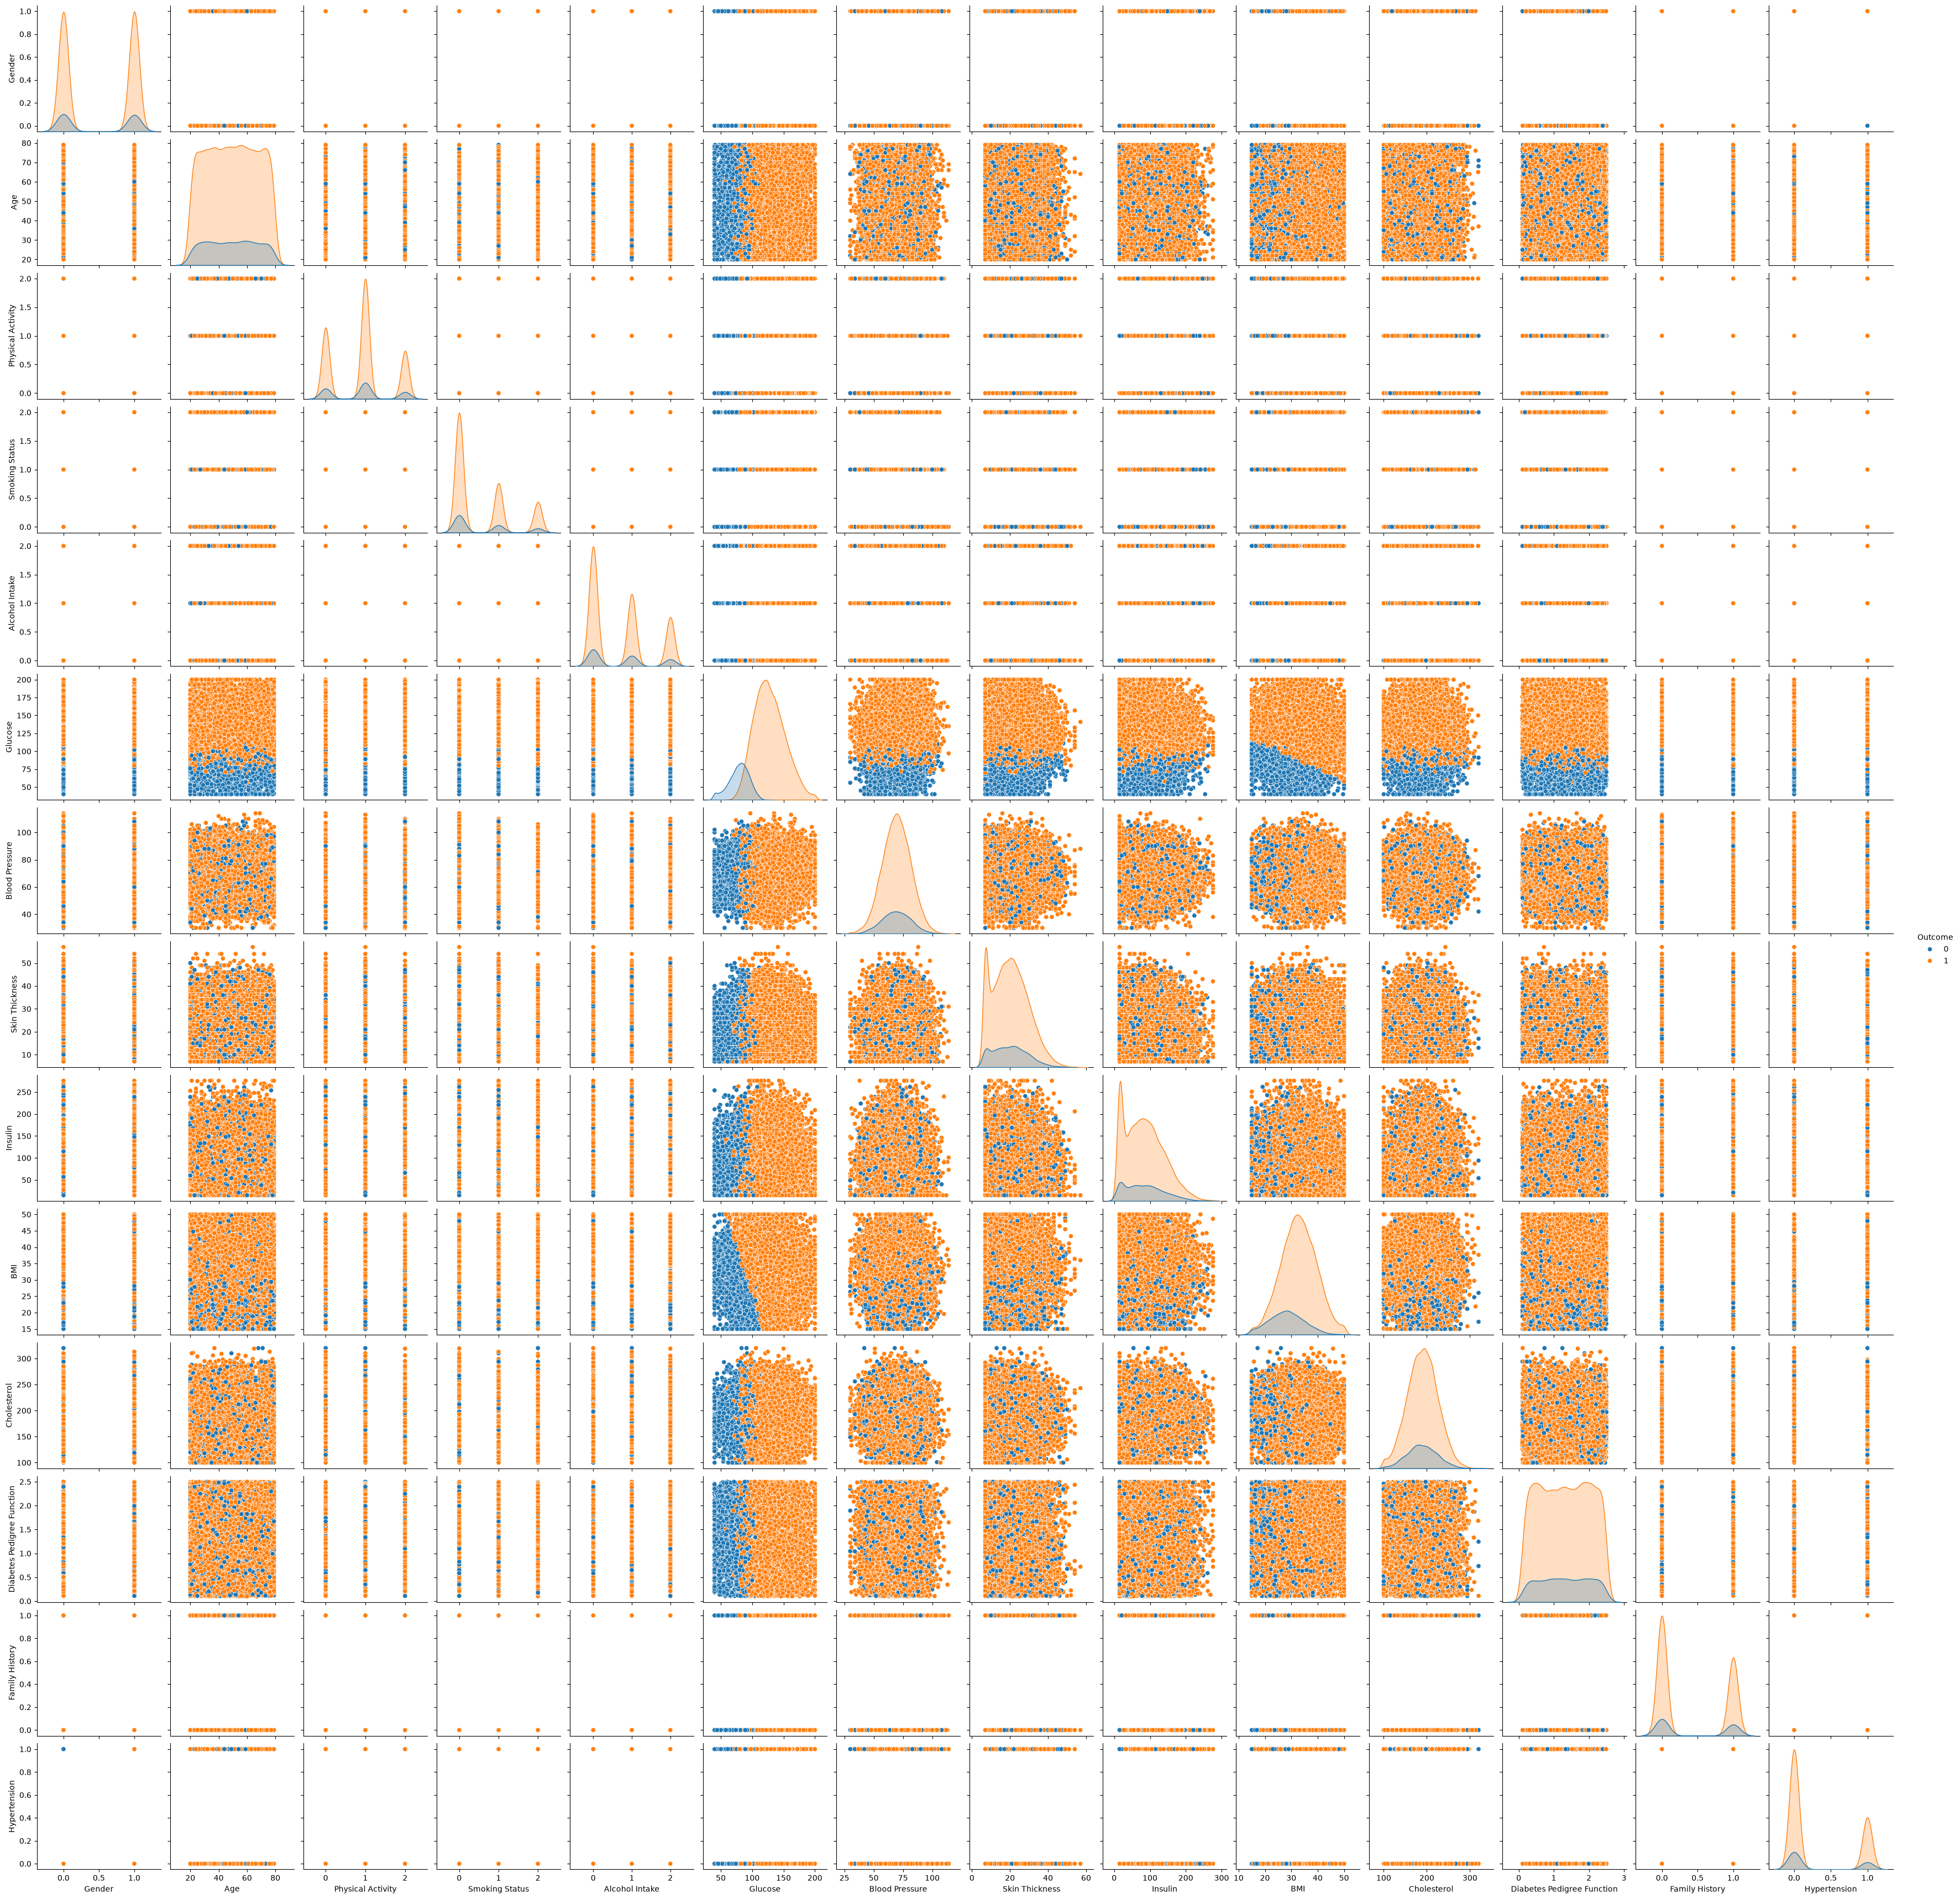

In [37]:

sns.pairplot(data= df, hue='Outcome', diag_kind='kde') # hue: name of variable in data
plt.show()
# 여기서 산점도로 알 수 있는 건 glucose 가 가장 영향이 깊다고 알 수 있다. 

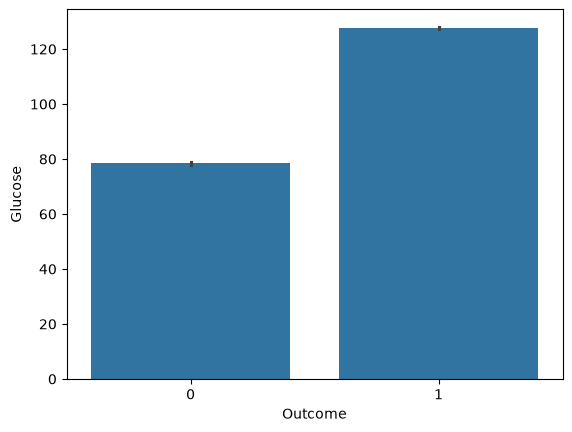

In [36]:
sns.barplot(x='Outcome', y='Glucose', data=df)
plt.show()

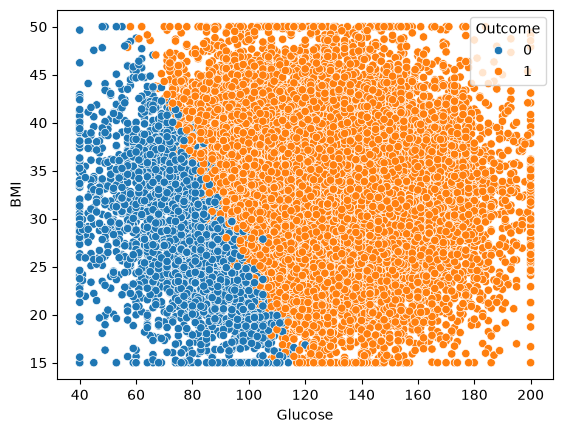

In [38]:
sns.scatterplot(data=df, x='Glucose', y='BMI',  hue='Outcome')  # 0(정상)과 1(당뇨)에 따라 색상 분기)
plt.show()
# 전체적으로 bmi 가 큰 영향을 미치진 않지만 gloucouse가 기본적으로 낮으면 bmi도 낮아서 대각선으로 나타난다

<Axes: xlabel='Outcome', ylabel='BMI'>

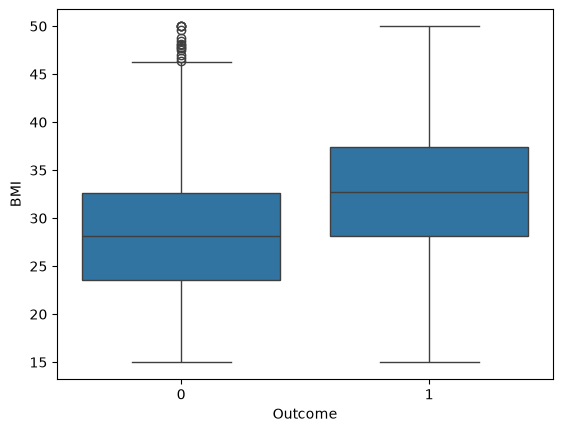

In [39]:
sns.boxplot(x='Outcome', y='BMI', data=df)

<Axes: xlabel='Outcome', ylabel='Glucose'>

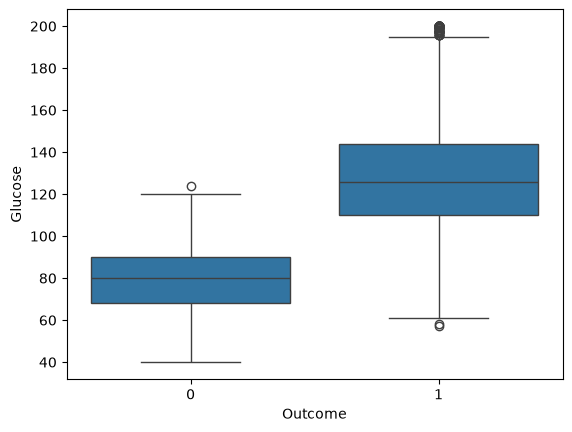

In [40]:
sns.boxplot(x='Outcome', y='Glucose', data=df)


<Axes: xlabel='Outcome', ylabel='Age'>

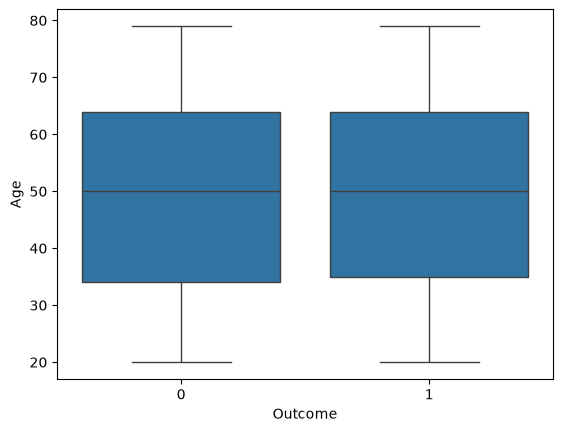

In [ ]:
sns.boxplot(x='Outcome', y='Age', data=df) 

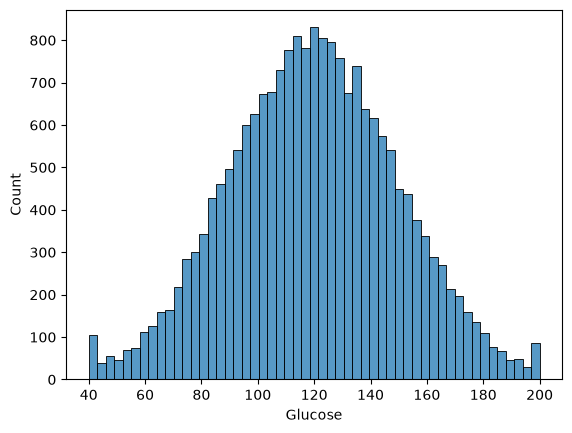

In [ ]:
sns.histplot(df,x='Glucose')
plt.show()

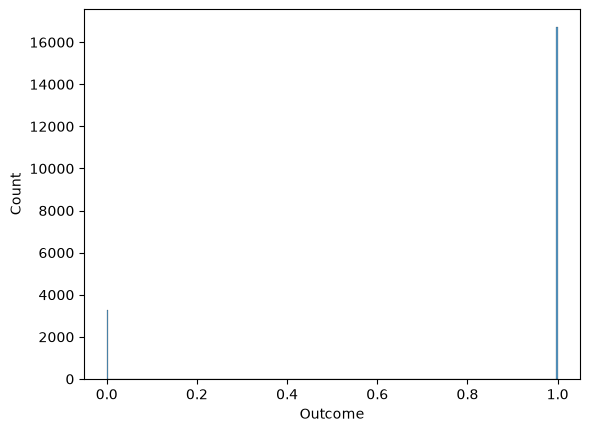

In [ ]:
sns.histplot(df,x='Outcome')
plt.show()

"수치형 변수들의 박스플롯을 분석한 결과, 여러 변수(특히 Glucose, Insulin 등)에서 다수의 이상치가 관측되었습니다. 이는 데이터 수집 오류나 노이즈가 아니라, 당뇨병 환자 집단 특유의 극단적인 생체 지표 분포(오른쪽으로 치우친 형태)를 반영하는 실제 임상 데이터의 특성입니다. 머신러닝 모델(예: Random Forest 등 앙상블 모델)은 트리 기반 구조 특성상 이러한 이상치에 비교적 강건(Robust)하므로, 별도의 과도한 제거 없이 원본 분포를 유지한 채 모델 학습에 활용하였습니다."

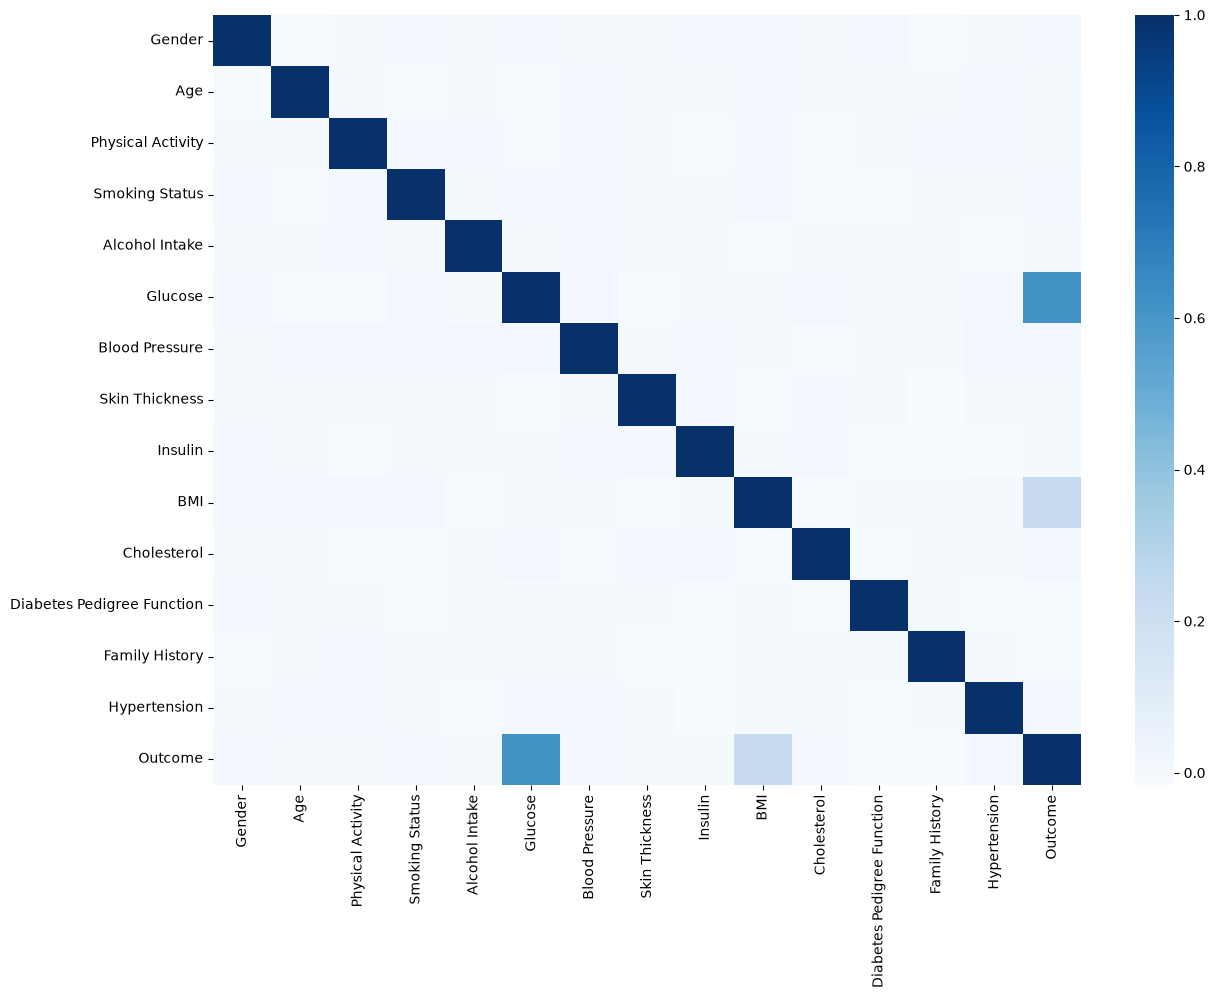

In [47]:
plt.figure(figsize=(14, 10))

corr = df.select_dtypes(include='number').corr()

sns.heatmap(
    corr,
    annot=False,  #False : hide numbers
    cmap='Blues'
)
plt.show()


# SVC (test size 25%)

In [48]:
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.svm import SVC
from sklearn.tree import plot_tree

In [49]:
X_svc_25=df.drop(columns=['Outcome'])
y_svc_25=df['Outcome']

X_svc_25_train, X_svc_25_test, y_svc_25_train, y_svc_25_test = train_test_split(X_svc_25,y_svc_25, test_size=0.25, random_state=42)

In [50]:
print(X_svc_25_train.shape, X_svc_25_test.shape, y_svc_25_train.shape, y_svc_25_test.shape)

(15000, 14) (5000, 14) (15000,) (5000,)


In [ ]:
from sklearn import set_config

set_config(display='text') # cp949 와 관련한 에러가 뜨면서 여기서부터 파일 자체를 못 읽고 다음 파트를 진행할 수 없어서 setfig display=text로 도표 등으로 읽히던 데이터를 완전히 text로 변환

In [ ]:
svc_25_model = SVC()
svc_25_model.fit(X_svc_25_train, y_svc_25_train)

SVC()

In [ ]:


# Make predictions using the model
y_svc_25_predict = svc_25_model.predict(X_svc_25_test)

<Figure size 640x480 with 0 Axes>

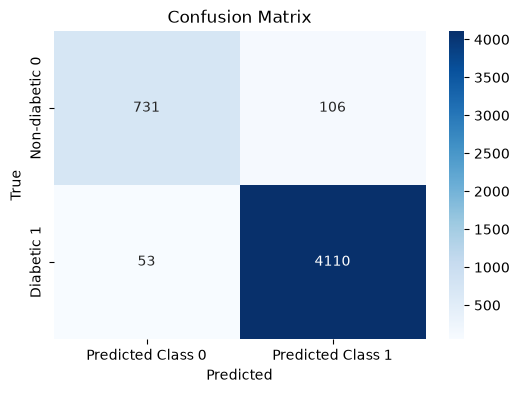

In [ ]:

from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm_svc_25= confusion_matrix(y_svc_25_test, y_svc_25_predict)

# **Ensure previous plots are cleared**
plt.clf()  # Clear the previous plot before rendering a new one
plt.figure(figsize = (6, 4))  # Define figure size to avoid residual elements

# Create a heatmap for the confusion matrix
sns.heatmap(cm_svc_25, annot = True, fmt = 'd', cmap = 'Blues', 
            xticklabels=['Predicted Class 0', 'Predicted Class 1'], 
            yticklabels=['Non-diabetic 0', 'Diabetic 1'])

# Add labels and title
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')

# Show the plot
plt.show()

In [ ]:
from sklearn.metrics import classification_report
# Print classification report
print(classification_report(y_svc_25_test, y_svc_25_predict))

              precision    recall  f1-score   support

           0       0.93      0.87      0.90       837
           1       0.97      0.99      0.98      4163

    accuracy                           0.97      5000
   macro avg       0.95      0.93      0.94      5000
weighted avg       0.97      0.97      0.97      5000



In [ ]:
#normalized scaler - fit&transform on train, fit only on test
from sklearn.preprocessing import StandardScaler
n_svc_25_scaler = StandardScaler()
X_svc_25_train_scaled = n_svc_25_scaler.fit_transform(X_svc_25_train.astype(float))
X_svc_25_test_scaled = n_svc_25_scaler.transform(X_svc_25_test.astype(float))

#Support Vector Classification model -  apply on scaled data
svc_25_model_scaled = SVC()
svc_25_model_scaled.fit(X_svc_25_train_scaled, y_svc_25_train)

SVC()

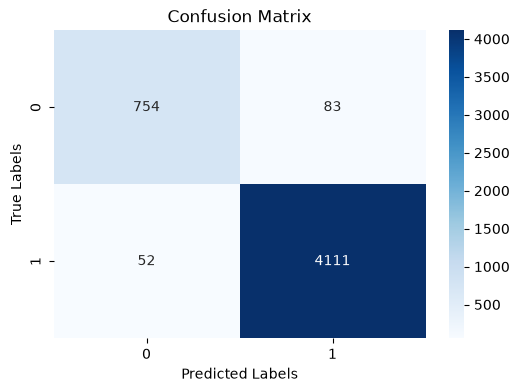

In [58]:
# Predict
y_svc_25_predict_scaled = svc_25_model_scaled.predict(X_svc_25_test_scaled)

# Confusion matrix
cm_svc_25_scaled = confusion_matrix(y_svc_25_test, y_svc_25_predict_scaled)

# Plot confusion matrix
plt.figure(figsize = (6, 4))
sns.heatmap(cm_svc_25_scaled, annot = True, fmt = 'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()   # <-- REQUIRED to display the plot outside Jupyter


In [ ]:
# Print classification report
from sklearn.metrics import classification_report
print(classification_report(y_svc_25_test, y_svc_25_predict_scaled))
#조금 나아졋지만 크게 영향 미칠 정도는 아니다

              precision    recall  f1-score   support

           0       0.94      0.90      0.92       837
           1       0.98      0.99      0.98      4163

    accuracy                           0.97      5000
   macro avg       0.96      0.94      0.95      5000
weighted avg       0.97      0.97      0.97      5000



Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV 1/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.838 total time=  28.3s
[CV 2/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.838 total time=  27.3s
[CV 3/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.838 total time=  27.1s
[CV 4/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.837 total time=  27.1s
[CV 5/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.837 total time=  27.2s
[CV 1/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.944 total time=   4.3s
[CV 2/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.949 total time=   4.1s
[CV 3/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.952 total time=   4.0s
[CV 4/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.945 total time=   4.2s
[CV 5/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.945 total time=   4.1s
[CV 1/5] END .....C=0.1, gamma=0.01, kernel=rbf;, score=0.943 total time=   4.1s
[CV 2/5] END .....C=0.1, gamma=0.01, kernel=rbf

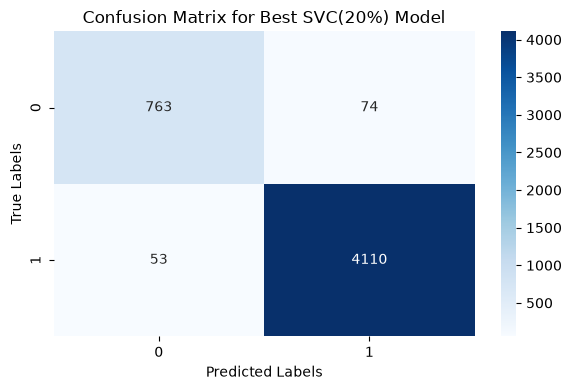

In [ ]:

from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10, 100, 1000],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf']
}

grid = GridSearchCV(SVC(), param_grid, verbose=4)
grid.fit(X_svc_25_train_scaled, y_svc_25_train)


print("Best Parameters:", grid.best_params_)
print("Best Estimator:", grid.best_estimator_)


grid_svc_25_predictions = grid.predict(X_svc_25_test_scaled)


cmG_svc_25 = confusion_matrix(y_svc_25_test, grid_svc_25_predictions)


plt.figure(figsize = (6,4))
sns.heatmap(cmG_svc_25, annot = True, fmt =  'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for Best SVC(25%) Model')
plt.tight_layout()
plt.show()   

In [ ]:
# Print classification report
print(classification_report(y_svc_25_test, grid_svc_25_predictions))


Classification Report:

              precision    recall  f1-score   support

           0       0.94      0.91      0.92       837
           1       0.98      0.99      0.98      4163

    accuracy                           0.97      5000
   macro avg       0.96      0.95      0.95      5000
weighted avg       0.97      0.97      0.97      5000



# SVC (Test size 20 %) - best

In [62]:
X_svc_20=df.drop(columns=['Outcome'])
y_svc_20=df['Outcome']

X_svc_20_train, X_svc_20_test, y_svc_20_train, y_svc_20_test = train_test_split(X_svc_20,y_svc_20, test_size=0.2, random_state=42)

In [63]:
print(X_svc_20_train.shape, X_svc_20_test.shape, y_svc_20_train.shape, y_svc_20_test.shape)

(16000, 14) (4000, 14) (16000,) (4000,)


In [ ]:
svc_20_model = SVC()
svc_20_model.fit(X_svc_20_train, y_svc_20_train)


SVC()

In [ ]:
# Make predictions using the model
y_svc_20_predict = svc_20_model.predict(X_svc_20_test)

<Figure size 640x480 with 0 Axes>

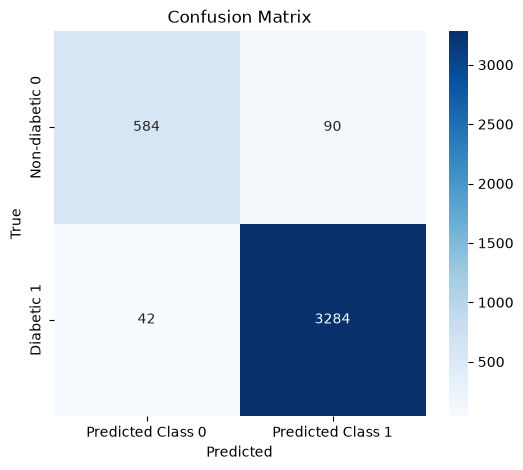

In [ ]:
# Generate confusion matrix
cm_svc_20= confusion_matrix(y_svc_20_test, y_svc_20_predict)

# **Ensure previous plots are cleared**
plt.clf()  # Clear the previous plot before rendering a new one
plt.figure(figsize = (6, 5))  # Define figure size to avoid residual elements

# Create a heatmap for the confusion matrix
sns.heatmap(cm_svc_20, annot = True, fmt = 'd', cmap = 'Blues', 
            xticklabels=['Predicted Class 0', 'Predicted Class 1'], 
            yticklabels=['Non-diabetic 0', 'Diabetic 1'])

# Add labels and title
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')

# Show the plot
plt.show()

In [68]:
# Print classification report
print(classification_report(y_svc_20_test, y_svc_20_predict))

              precision    recall  f1-score   support

           0       0.93      0.87      0.90       674
           1       0.97      0.99      0.98      3326

    accuracy                           0.97      4000
   macro avg       0.95      0.93      0.94      4000
weighted avg       0.97      0.97      0.97      4000



In [ ]:
#normalized scaler - fit&transform on train, fit only on test

n_svc_20_scaler = StandardScaler()
X_svc_20_train_scaled = n_svc_20_scaler.fit_transform(X_svc_20_train.astype(float))
X_svc_20_test_scaled = n_svc_20_scaler.transform(X_svc_20_test.astype(float))

#Support Vector Classification model -  apply on scaled data

svc_20_model_scaled = SVC()
svc_20_model_scaled.fit(X_svc_20_train_scaled, y_svc_20_train)

SVC()

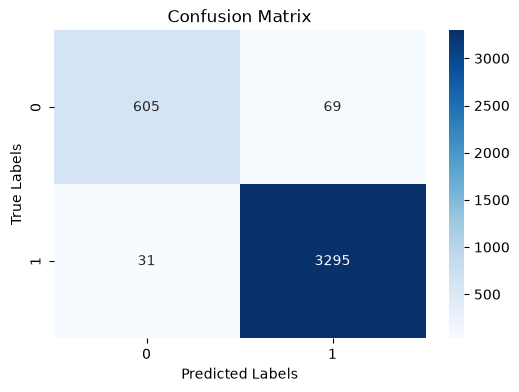

In [70]:
# Predict
y_svc_20_predict_scaled = svc_20_model_scaled.predict(X_svc_20_test_scaled)

# Confusion matrix
cm_svc_20_scaled = confusion_matrix(y_svc_20_test, y_svc_20_predict_scaled)

# Plot confusion matrix
plt.figure(figsize = (6, 4))
sns.heatmap(cm_svc_20_scaled, annot = True, fmt = 'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()   # <-- REQUIRED to display the plot outside Jupyter


In [71]:
# Print classification report
print(classification_report(y_svc_20_test, y_svc_20_predict_scaled))
#조금 나아졋지만 크게 영향 미칠 정도는 아니다

              precision    recall  f1-score   support

           0       0.95      0.90      0.92       674
           1       0.98      0.99      0.99      3326

    accuracy                           0.97      4000
   macro avg       0.97      0.94      0.95      4000
weighted avg       0.97      0.97      0.97      4000



Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV 1/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.838 total time=  35.6s
[CV 2/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.838 total time=  33.2s
[CV 3/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.838 total time=  32.3s
[CV 4/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.838 total time=  32.5s
[CV 5/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.838 total time=  32.2s
[CV 1/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.949 total time=   4.4s
[CV 2/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.952 total time=   4.5s
[CV 3/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.956 total time=   4.3s
[CV 4/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.947 total time=   4.5s
[CV 5/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.945 total time=   4.3s
[CV 1/5] END .....C=0.1, gamma=0.01, kernel=rbf;, score=0.945 total time=   4.5s
[CV 2/5] END .....C=0.1, gamma=0.01, kernel=rbf

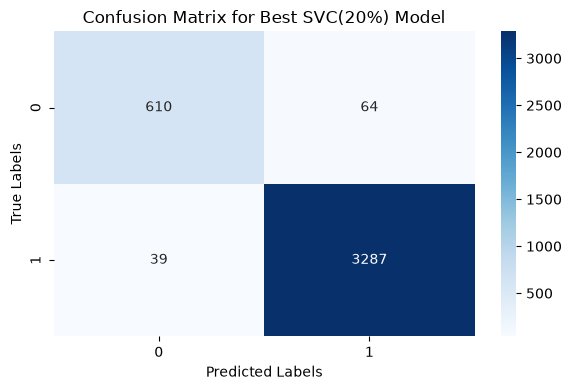

In [ ]:



param_grid = {
    'C': [0.1, 1, 10, 100, 1000],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf']
}

grid = GridSearchCV(SVC(), param_grid, verbose=4)
grid.fit(X_svc_20_train_scaled, y_svc_20_train)


print("Best Parameters:", grid.best_params_)
print("Best Estimator:", grid.best_estimator_)


grid_svc_20_predictions = grid.predict(X_svc_20_test_scaled)


cmG_svc_20 = confusion_matrix(y_svc_20_test, grid_svc_20_predictions)


plt.figure(figsize = (6,4))
sns.heatmap(cmG_svc_20, annot = True, fmt =  'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for Best SVC(20%) Model')
plt.tight_layout()
plt.show()   

In [73]:
# Print classification report
print("\nClassification Report:\n")
print(classification_report(y_svc_20_test, grid_svc_20_predictions))


Classification Report:

              precision    recall  f1-score   support

           0       0.94      0.91      0.92       674
           1       0.98      0.99      0.98      3326

    accuracy                           0.97      4000
   macro avg       0.96      0.95      0.95      4000
weighted avg       0.97      0.97      0.97      4000



# SVC (Test size 15%)

In [74]:
X_svc_15=df.drop(columns=['Outcome'])
y_svc_15=df['Outcome']

X_svc_15_train, X_svc_15_test, y_svc_15_train, y_svc_15_test = train_test_split(X_svc_15,y_svc_15, test_size=0.15, random_state=42)

In [75]:
print(X_svc_15_train.shape, X_svc_15_test.shape, y_svc_15_train.shape, y_svc_15_test.shape)

(17000, 14) (3000, 14) (17000,) (3000,)


In [76]:


svc_15_model = SVC()
svc_15_model.fit(X_svc_15_train, y_svc_15_train)


SVC()

In [77]:


# Make predictions using the model
y_svc_15_predict = svc_15_model.predict(X_svc_15_test)

<Figure size 640x480 with 0 Axes>

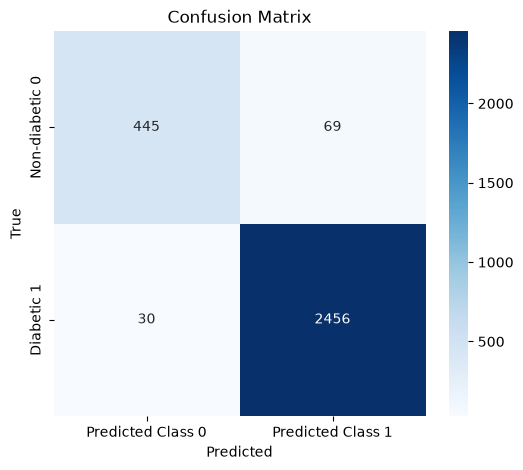

In [78]:

# Generate confusion matrix
cm_svc_15= confusion_matrix(y_svc_15_test, y_svc_15_predict)

# **Ensure previous plots are cleared**
plt.clf()  # Clear the previous plot before rendering a new one
plt.figure(figsize = (6, 5))  # Define figure size to avoid residual elements

# Create a heatmap for the confusion matrix
sns.heatmap(cm_svc_15, annot = True, fmt = 'd', cmap = 'Blues', 
            xticklabels=['Predicted Class 0', 'Predicted Class 1'], 
            yticklabels=['Non-diabetic 0', 'Diabetic 1'])

# Add labels and title
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')

# Show the plot
plt.show()

In [79]:
# Print classification report
print(classification_report(y_svc_15_test, y_svc_15_predict))

              precision    recall  f1-score   support

           0       0.94      0.87      0.90       514
           1       0.97      0.99      0.98      2486

    accuracy                           0.97      3000
   macro avg       0.95      0.93      0.94      3000
weighted avg       0.97      0.97      0.97      3000



In [80]:

n_svc_15_scaler = StandardScaler()
X_svc_15_train_scaled = n_svc_15_scaler.fit_transform(X_svc_15_train.astype(float))
X_svc_15_test_scaled = n_svc_15_scaler.transform(X_svc_15_test.astype(float))


svc_15_model_scaled = SVC()
svc_15_model_scaled.fit(X_svc_15_train_scaled, y_svc_15_train)

SVC()

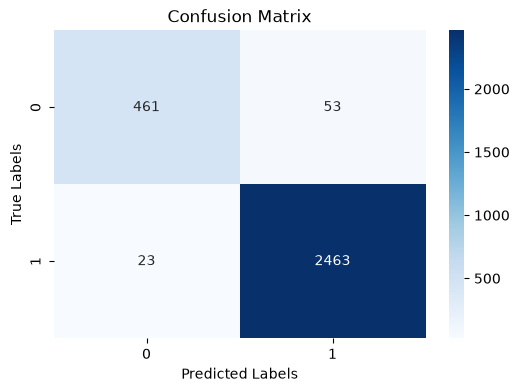

In [81]:
# Predict
y_svc_15_predict_scaled = svc_15_model_scaled.predict(X_svc_15_test_scaled)

# Confusion matrix
cm_svc_15_scaled = confusion_matrix(y_svc_15_test, y_svc_15_predict_scaled)

# Plot confusion matrix
plt.figure(figsize = (6, 4))
sns.heatmap(cm_svc_15_scaled, annot = True, fmt = 'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()   # <-- REQUIRED to display the plot outside Jupyter


In [82]:
# Print classification report
print(classification_report(y_svc_15_test, y_svc_15_predict_scaled))
#조금 나아졋지만 크게 영향 미칠 정도는 아니다

              precision    recall  f1-score   support

           0       0.95      0.90      0.92       514
           1       0.98      0.99      0.98      2486

    accuracy                           0.97      3000
   macro avg       0.97      0.94      0.95      3000
weighted avg       0.97      0.97      0.97      3000



Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV 1/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.838 total time=  36.1s
[CV 2/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.838 total time=  36.5s
[CV 3/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.838 total time=  36.6s
[CV 4/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.838 total time=  36.4s
[CV 5/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.838 total time=  36.4s
[CV 1/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.954 total time=   4.9s
[CV 2/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.951 total time=   4.9s
[CV 3/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.956 total time=   4.8s
[CV 4/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.951 total time=   4.9s
[CV 5/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.946 total time=   5.0s
[CV 1/5] END .....C=0.1, gamma=0.01, kernel=rbf;, score=0.948 total time=   5.1s
[CV 2/5] END .....C=0.1, gamma=0.01, kernel=rbf

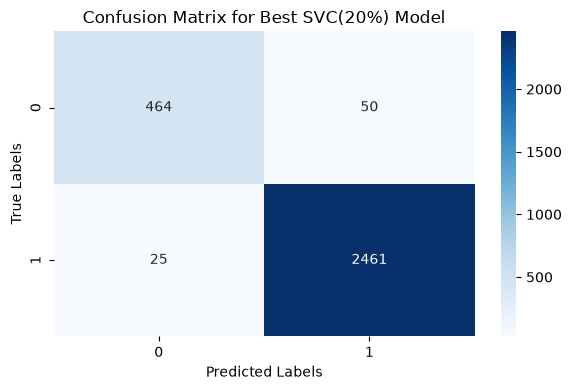

In [ ]:


param_grid = {
    'C': [0.1, 1, 10, 100, 1000],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf']
}

grid = GridSearchCV(SVC(), param_grid, verbose=4)
grid.fit(X_svc_15_train_scaled, y_svc_15_train)


print("Best Parameters:", grid.best_params_)
print("Best Estimator:", grid.best_estimator_)


grid_svc_15_predictions = grid.predict(X_svc_15_test_scaled)


cmG_svc_15 = confusion_matrix(y_svc_15_test, grid_svc_15_predictions)

plt.figure(figsize = (6,4))
sns.heatmap(cmG_svc_15, annot = True, fmt =  'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for Best SVC(15%) Model')
plt.tight_layout()
plt.show()   

In [84]:
# Print classification report
print("\nClassification Report:\n")
print(classification_report(y_svc_15_test, grid_svc_15_predictions))


Classification Report:

              precision    recall  f1-score   support

           0       0.95      0.90      0.93       514
           1       0.98      0.99      0.98      2486

    accuracy                           0.97      3000
   macro avg       0.96      0.95      0.96      3000
weighted avg       0.97      0.97      0.97      3000



# SVC (test size 5%)

In [85]:
X_svc_5=df.drop(columns=['Outcome'])
y_svc_5=df['Outcome']

X_svc_5_train, X_svc_5_test, y_svc_5_train, y_svc_5_test = train_test_split(X_svc_5,y_svc_5, test_size=0.05, random_state=42)

In [86]:
print(X_svc_5_train.shape, X_svc_5_test.shape, y_svc_5_train.shape, y_svc_5_test.shape)

(19000, 14) (1000, 14) (19000,) (1000,)


In [87]:


svc_5_model = SVC()
svc_5_model.fit(X_svc_5_train, y_svc_5_train)


SVC()

In [88]:


# Make predictions using the model
y_svc_5_predict = svc_5_model.predict(X_svc_5_test)

<Figure size 640x480 with 0 Axes>

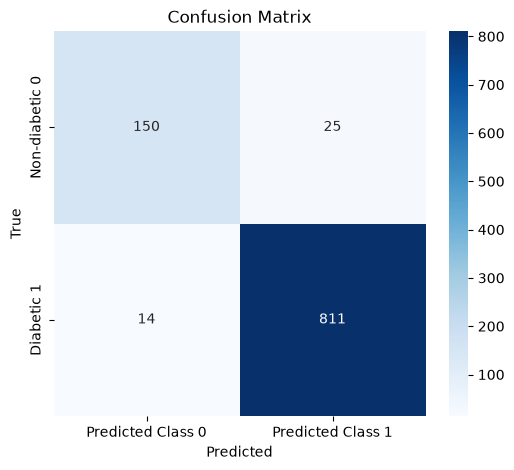

In [89]:

# Generate confusion matrix
cm_svc_5= confusion_matrix(y_svc_5_test, y_svc_5_predict)

# **Ensure previous plots are cleared**
plt.clf()  # Clear the previous plot before rendering a new one
plt.figure(figsize = (6, 5))  # Define figure size to avoid residual elements

# Create a heatmap for the confusion matrix
sns.heatmap(cm_svc_5, annot = True, fmt = 'd', cmap = 'Blues', 
            xticklabels=['Predicted Class 0', 'Predicted Class 1'], 
            yticklabels=['Non-diabetic 0', 'Diabetic 1'])

# Add labels and title
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')

# Show the plot
plt.show()

In [90]:
# Print classification report
print(classification_report(y_svc_5_test, y_svc_5_predict))

              precision    recall  f1-score   support

           0       0.91      0.86      0.88       175
           1       0.97      0.98      0.98       825

    accuracy                           0.96      1000
   macro avg       0.94      0.92      0.93      1000
weighted avg       0.96      0.96      0.96      1000



In [91]:

n_svc_5_scaler = StandardScaler()
X_svc_5_train_scaled = n_svc_5_scaler.fit_transform(X_svc_5_train.astype(float))
X_svc_5_test_scaled = n_svc_5_scaler.transform(X_svc_5_test.astype(float))

svc_5_model_scaled = SVC()
svc_5_model_scaled.fit(X_svc_5_train_scaled, y_svc_5_train)

SVC()

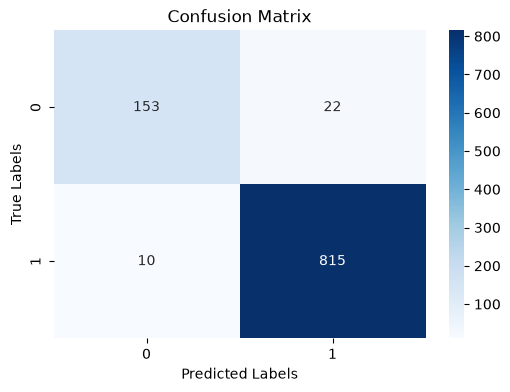

In [92]:
# Predict
y_svc_5_predict_scaled = svc_5_model_scaled.predict(X_svc_5_test_scaled)

# Confusion matrix
cm_svc_5_scaled = confusion_matrix(y_svc_5_test, y_svc_5_predict_scaled)

# Plot confusion matrix
plt.figure(figsize = (6, 4))
sns.heatmap(cm_svc_5_scaled, annot = True, fmt = 'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()   # <-- REQUIRED to display the plot outside Jupyter


In [93]:
# Print classification report
print(classification_report(y_svc_5_test, y_svc_5_predict_scaled))
#조금 나아졋지만 크게 영향 미칠 정도는 아니다

              precision    recall  f1-score   support

           0       0.94      0.87      0.91       175
           1       0.97      0.99      0.98       825

    accuracy                           0.97      1000
   macro avg       0.96      0.93      0.94      1000
weighted avg       0.97      0.97      0.97      1000



Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV 1/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.837 total time=  28.0s
[CV 2/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.837 total time=  24.9s
[CV 3/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.837 total time=  28.9s
[CV 4/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.837 total time=  29.4s
[CV 5/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.837 total time=  29.6s
[CV 1/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.959 total time=   4.0s
[CV 2/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.955 total time=   3.8s
[CV 3/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.958 total time=   4.0s
[CV 4/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.954 total time=   3.9s
[CV 5/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.952 total time=   4.1s
[CV 1/5] END .....C=0.1, gamma=0.01, kernel=rbf;, score=0.954 total time=   4.4s
[CV 2/5] END .....C=0.1, gamma=0.01, kernel=rbf

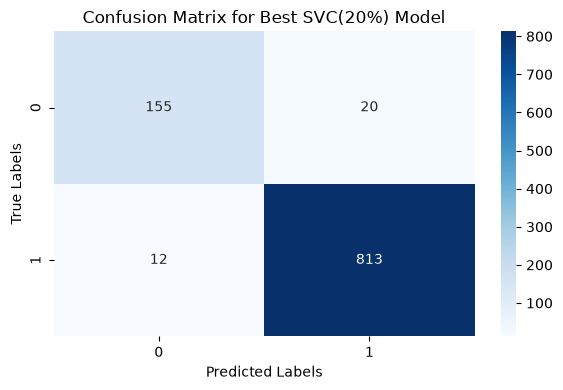

In [ ]:

param_grid = {
    'C': [0.1, 1, 10, 100, 1000],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf']
}

grid = GridSearchCV(SVC(), param_grid, verbose=4)
grid.fit(X_svc_5_train_scaled, y_svc_5_train)


print("Best Parameters:", grid.best_params_)
print("Best Estimator:", grid.best_estimator_)


grid_svc_5_predictions = grid.predict(X_svc_5_test_scaled)

cmG_svc_5 = confusion_matrix(y_svc_5_test, grid_svc_5_predictions)


plt.figure(figsize = (6,4))
sns.heatmap(cmG_svc_5, annot = True, fmt =  'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for Best SVC(5%) Model')
plt.tight_layout()
plt.show()   

In [95]:
# Print classification report
print("\nClassification Report:\n")
print(classification_report(y_svc_5_test, grid_svc_5_predictions))


Classification Report:

              precision    recall  f1-score   support

           0       0.93      0.89      0.91       175
           1       0.98      0.99      0.98       825

    accuracy                           0.97      1000
   macro avg       0.95      0.94      0.94      1000
weighted avg       0.97      0.97      0.97      1000



# SVC( cross validation)

In [96]:
X= df.drop(columns=['Outcome'])
y=df['Outcome']

In [97]:
from sklearn.model_selection import cross_val_score

# Create an initialise an object 'nvclassifier' by calling a method 'GaussianNB()'
nvclassifier = SVC()

# Calculate the score using cross validation method
cross_val_score = cross_val_score(nvclassifier, X, y, scoring = 'accuracy', cv = 10).mean() #cv=10-Fold Cross Validation(10겹 교차 검증)
#choose one as testing, and the others for training. for second, choose another one as testing and the others for training. and repeat it for 10 times.

print(cross_val_score) #데이터를 10개 그룹으로 나누고 10번의 교차검증을 마치고 난 후(1번째 - 1번이 평가 2-10까지 학습. 2번째 - 2번이 평가 1,3-10이 학습 ...), 10번의 정확도를 평균을 낸다.

0.97395


# Random Forest (Test size 25%)

In [98]:
from sklearn import tree
from sklearn.tree import plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import r2_score


In [99]:
X_rf_25=df.drop(columns=['Outcome'])
y_rf_25=df['Outcome']

In [100]:
X_rf_25_train, X_rf_25_test,y_rf_25_train, y_rf_25_test = train_test_split(X_rf_25,y_rf_25, test_size=0.25, random_state=0)
X_rf_25_train.shape, X_rf_25_test.shape,y_rf_25_train.shape, y_rf_25_test.shape

((15000, 14), (5000, 14), (15000,), (5000,))

In [101]:
clf_rf_25=RandomForestClassifier(class_weight='balanced',criterion='gini',max_depth=4,random_state=0)
#이제 decisiontree 하는데 뭐를 criterion 잡고 max depth 설정
clf_rf_25=clf_rf_25.fit(X_rf_25_train,y_rf_25_train)
y_rf_25_predict=clf_rf_25.predict(X_rf_25_test)

In [102]:
results = pd.DataFrame({
    "y_rf_25_test (True)": y_rf_25_test.reset_index(drop=True),  # reset index for alignment
    "y_rf_25_predict (Predicted)": y_rf_25_predict
})

# Show first 20 rows for a quick view
print(results.head(20))

    y_rf_25_test (True)  y_rf_25_predict (Predicted)
0                     1                            1
1                     1                            1
2                     1                            1
3                     0                            0
4                     1                            0
5                     1                            1
6                     1                            1
7                     1                            1
8                     1                            1
9                     1                            1
10                    1                            0
11                    0                            0
12                    1                            1
13                    1                            1
14                    1                            1
15                    1                            1
16                    1                            1
17                    1                       

In [103]:
# If you also want to check correctness
results["Correct?"] = results["y_rf_25_test (True)"] == results["y_rf_25_predict (Predicted)"]

print(results.head(20))

    y_rf_25_test (True)  y_rf_25_predict (Predicted)  Correct?
0                     1                            1      True
1                     1                            1      True
2                     1                            1      True
3                     0                            0      True
4                     1                            0     False
5                     1                            1      True
6                     1                            1      True
7                     1                            1      True
8                     1                            1      True
9                     1                            1      True
10                    1                            0     False
11                    0                            0      True
12                    1                            1      True
13                    1                            1      True
14                    1                            1   

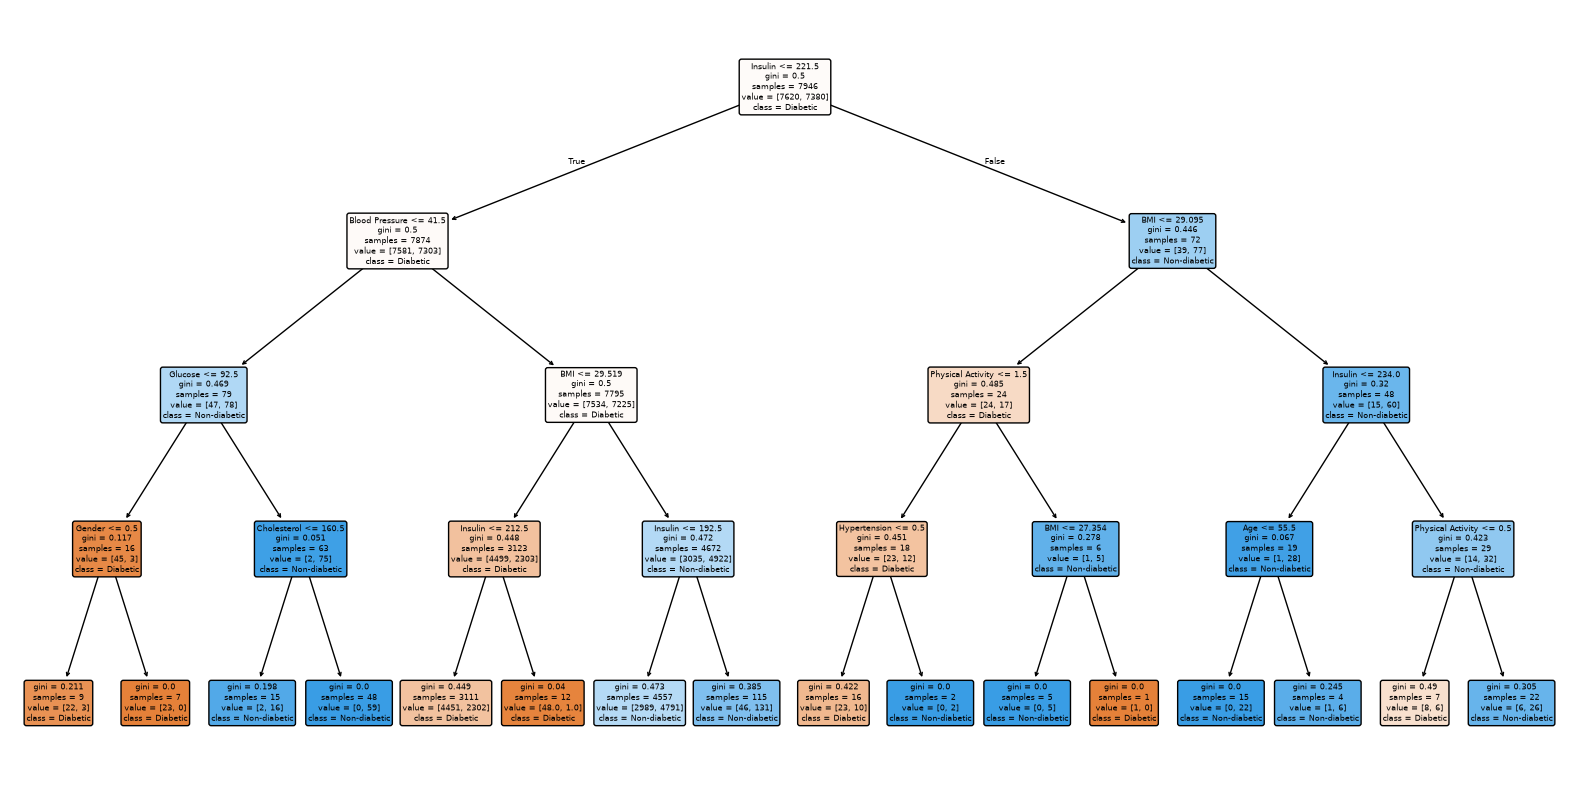

In [104]:
tree=clf_rf_25.estimators_[0]
plt.figure(figsize=(20,10))
plot_tree(tree, feature_names=X_rf_25.columns.tolist(),class_names=['Diabetic','Non-diabetic'],filled=True,rounded=True)
plt.show()

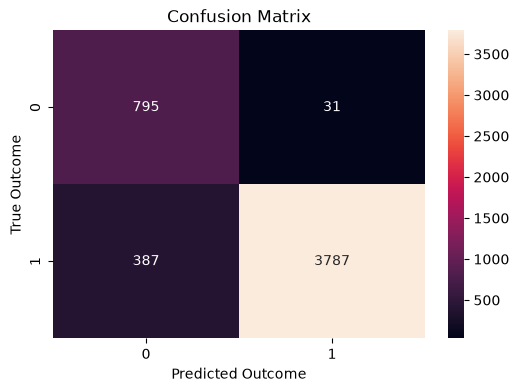

In [105]:
# Predict by using an object classifier 'clf'
y_rf_25_predict = clf_rf_25.predict(X_rf_25_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm_rf_25 = confusion_matrix(y_rf_25_test, y_rf_25_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm_rf_25, annot = True, fmt = 'd')        # 'd' stands for integer format
plt.xlabel('Predicted Outcome')
plt.ylabel('True Outcome')
plt.title('Confusion Matrix')
plt.show()

In [106]:
print(classification_report(y_rf_25_test, y_rf_25_predict))

              precision    recall  f1-score   support

           0       0.67      0.96      0.79       826
           1       0.99      0.91      0.95      4174

    accuracy                           0.92      5000
   macro avg       0.83      0.93      0.87      5000
weighted avg       0.94      0.92      0.92      5000



In [ ]:
#normalized scaler - fit&transform on train, fit only on test

n_rf_25_scaler = StandardScaler()
X_rf_25_train_scaled = n_rf_25_scaler.fit_transform(X_rf_25_train.astype(float))
X_rf_25_test_scaled = n_rf_25_scaler.transform(X_rf_25_test.astype(float))

clf_rf_25_scaled=RandomForestClassifier(class_weight='balanced',criterion='gini',max_depth=4,random_state=0)
#이제 decisiontree 하는데 뭐를 criterion 잡고 max depth 설정
clf_rf_25_scaled=clf_rf_25_scaled.fit(X_rf_25_train_scaled,y_rf_25_train)
y_rf_25_predict_scaled=clf_rf_25_scaled.predict(X_rf_25_test_scaled)



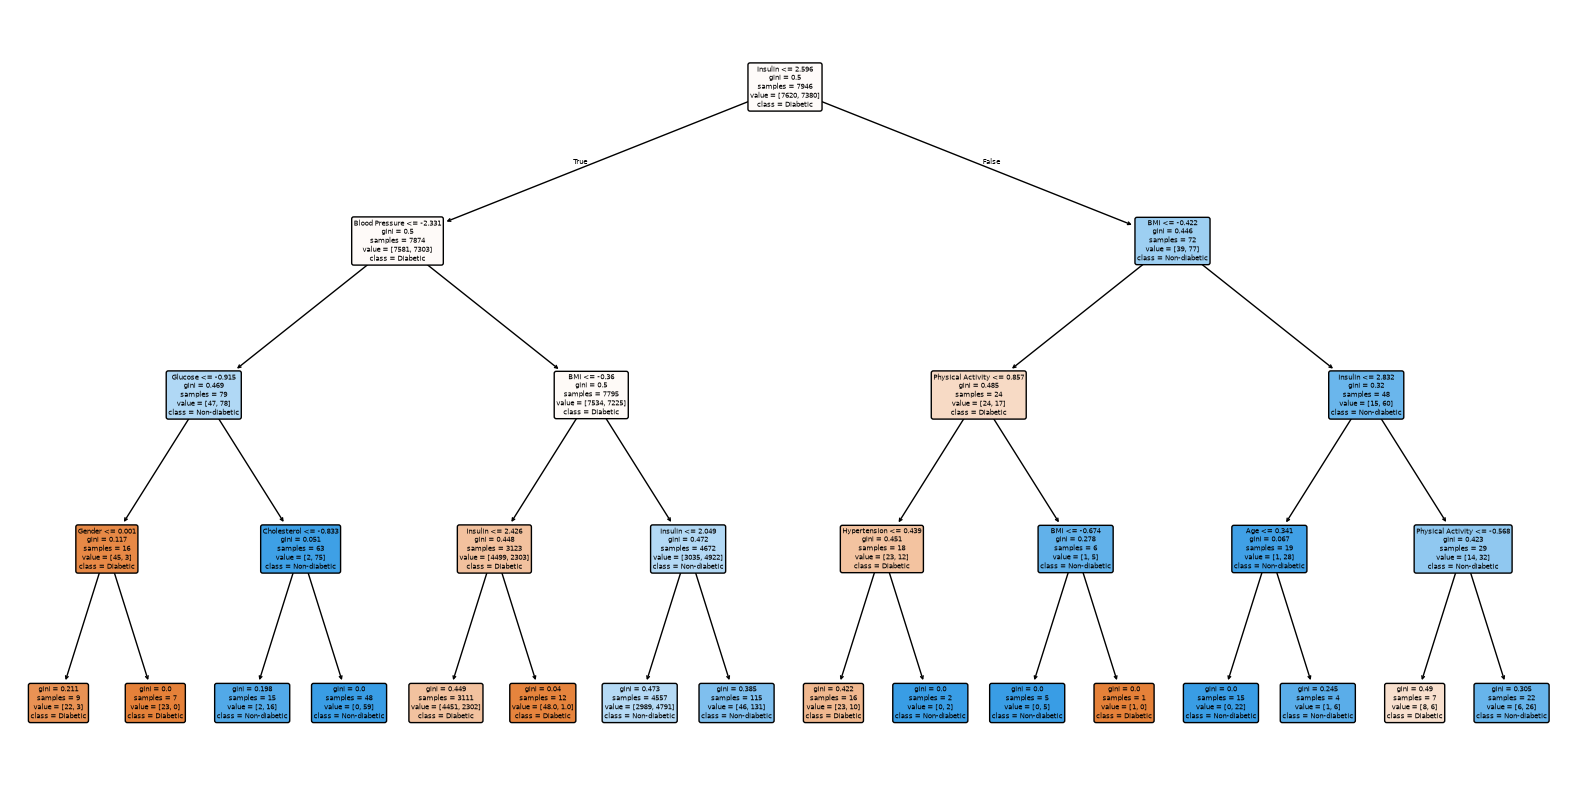

In [108]:
tree=clf_rf_25_scaled.estimators_[0]
plt.figure(figsize=(20,10))
plot_tree(tree, feature_names=X_rf_25.columns.tolist(),class_names=['Diabetic','Non-diabetic'],filled=True,rounded=True)
plt.show()

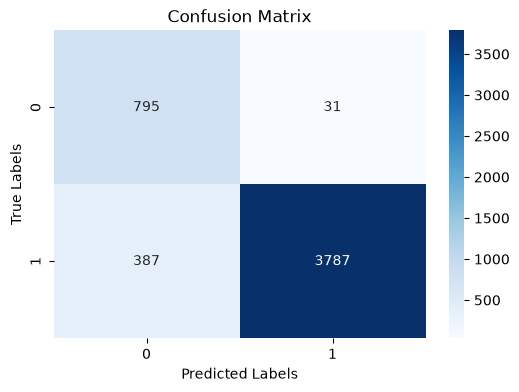

In [109]:

# Confusion matrix
cm_rf_25_scaled = confusion_matrix(y_rf_25_test, y_rf_25_predict_scaled)

# Plot confusion matrix
plt.figure(figsize = (6, 4))
sns.heatmap(cm_rf_25_scaled, annot = True, fmt = 'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()   # <-- REQUIRED to display the plot outside Jupyter



In [110]:
# Print classification report
print(classification_report(y_rf_25_test, y_rf_25_predict_scaled))

              precision    recall  f1-score   support

           0       0.67      0.96      0.79       826
           1       0.99      0.91      0.95      4174

    accuracy                           0.92      5000
   macro avg       0.83      0.93      0.87      5000
weighted avg       0.94      0.92      0.92      5000



In [ ]:


rf_25_grid = RandomForestClassifier()
rf_25_gr_space= {'max_depth': [3,5,7,10],
    'n_estimators': [100, 200, 300, 400, 500],
    'max_features': [10, 20, 30 , 40],
    'min_samples_leaf': [1, 2, 4]}

grid=GridSearchCV(rf_25_grid, rf_25_gr_space, cv=3, scoring='accuracy', verbose=4)
model_rf_25_grid = grid.fit(X_rf_25_train, y_rf_25_train)

print("Best Parameters:", grid.best_params_)
print("Best Estimator:", grid.best_estimator_)



Fitting 3 folds for each of 240 candidates, totalling 720 fits
[CV 1/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=100;, score=0.963 total time=   2.1s
[CV 2/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=100;, score=0.961 total time=   2.1s
[CV 3/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=100;, score=0.969 total time=   2.2s
[CV 1/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=200;, score=0.961 total time=   4.3s
[CV 2/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=200;, score=0.960 total time=   4.4s
[CV 3/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=200;, score=0.969 total time=   4.3s
[CV 1/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=300;, score=0.962 total time=   6.4s
[CV 2/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=300;, score=0.960 total time=   6.4s
[CV 3/3] END max_depth=3, max_fea

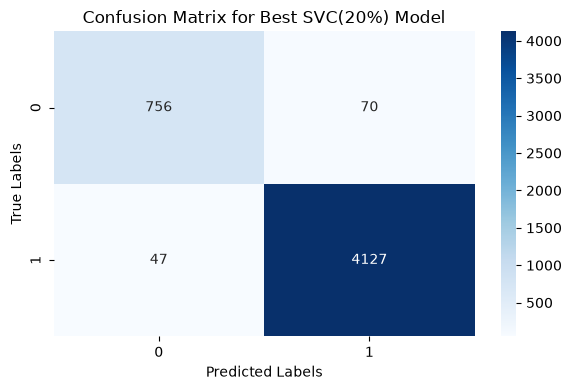

In [ ]:
grid_rf_25_predictions = grid.predict(X_rf_25_test)

cmG_rf_25 = confusion_matrix(y_rf_25_test, grid_rf_25_predictions)


plt.figure(figsize = (6,4))
sns.heatmap(cmG_rf_25, annot = True, fmt =  'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for Best SVC(25%) Model')
plt.tight_layout()
plt.show()   

In [113]:
# Print classification report
print("\nClassification Report:\n")
print(classification_report(y_rf_25_test, grid_rf_25_predictions))


Classification Report:

              precision    recall  f1-score   support

           0       0.94      0.92      0.93       826
           1       0.98      0.99      0.99      4174

    accuracy                           0.98      5000
   macro avg       0.96      0.95      0.96      5000
weighted avg       0.98      0.98      0.98      5000



# Random Forest ( test size 20%) - best

In [114]:
X_rf_20=df.drop(columns=['Outcome'])
y_rf_20=df['Outcome']

In [115]:
X_rf_20_train, X_rf_20_test,y_rf_20_train, y_rf_20_test = train_test_split(X_rf_20,y_rf_20, test_size=0.20, random_state=0)
X_rf_20_train.shape, X_rf_20_test.shape,y_rf_20_train.shape, y_rf_20_test.shape

((16000, 14), (4000, 14), (16000,), (4000,))

In [116]:
clf_rf_20=RandomForestClassifier(class_weight='balanced',criterion='gini',max_depth=4,random_state=0)
#이제 decisiontree 하는데 뭐를 criterion 잡고 max depth 설정
clf_rf_20=clf_rf_20.fit(X_rf_20_train,y_rf_20_train)
y_rf_20_predict=clf_rf_20.predict(X_rf_20_test)

In [117]:
results = pd.DataFrame({
    "y_rf_20_test (True)": y_rf_20_test.reset_index(drop=True),  # reset index for alignment
    "y_rf_20_predict (Predicted)": y_rf_20_predict
})

# Show first 20 rows for a quick view
print(results.head(20))

    y_rf_20_test (True)  y_rf_20_predict (Predicted)
0                     1                            1
1                     1                            1
2                     1                            1
3                     0                            0
4                     1                            1
5                     1                            1
6                     1                            1
7                     1                            1
8                     1                            1
9                     1                            1
10                    1                            0
11                    0                            0
12                    1                            1
13                    1                            1
14                    1                            1
15                    1                            1
16                    1                            1
17                    1                       

In [118]:
# If you also want to check correctness
results["Correct?"] = results["y_rf_20_test (True)"] == results["y_rf_20_predict (Predicted)"]

print(results.head(20))

    y_rf_20_test (True)  y_rf_20_predict (Predicted)  Correct?
0                     1                            1      True
1                     1                            1      True
2                     1                            1      True
3                     0                            0      True
4                     1                            1      True
5                     1                            1      True
6                     1                            1      True
7                     1                            1      True
8                     1                            1      True
9                     1                            1      True
10                    1                            0     False
11                    0                            0      True
12                    1                            1      True
13                    1                            1      True
14                    1                            1   

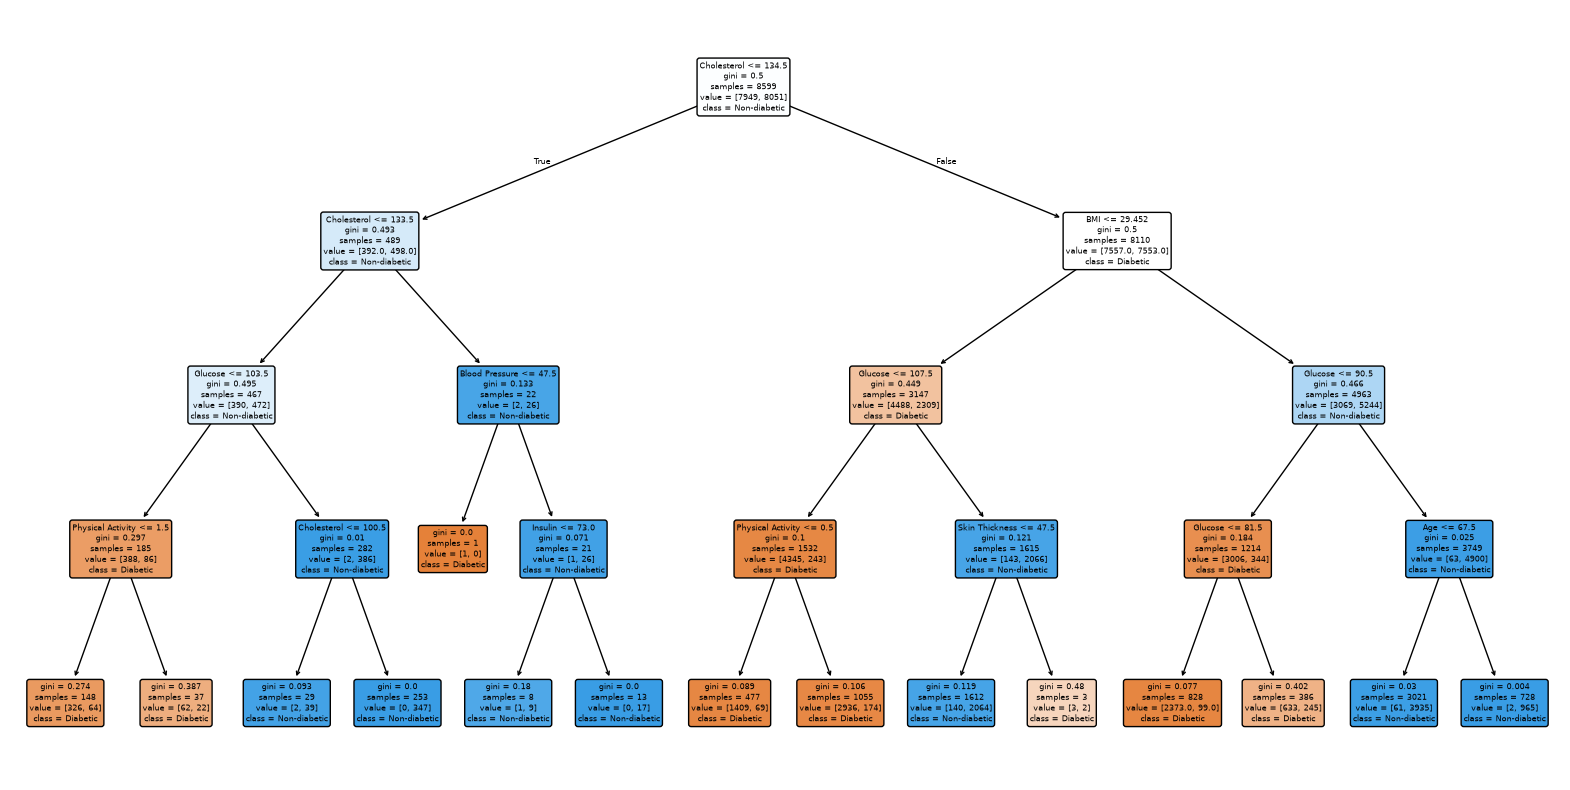

In [119]:
tree=clf_rf_20.estimators_[0]
plt.figure(figsize=(20,10))
plot_tree(tree, feature_names=X_rf_20.columns.tolist(),class_names=['Diabetic','Non-diabetic'],filled=True,rounded=True)
plt.show()

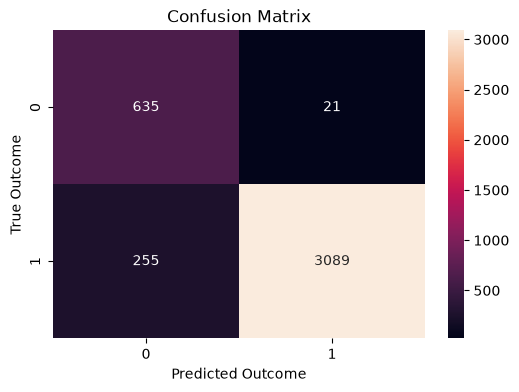

In [120]:
# Predict by using an object classifier 'clf'
y_rf_20_predict = clf_rf_20.predict(X_rf_20_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm_rf_20 = confusion_matrix(y_rf_20_test, y_rf_20_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm_rf_20, annot = True, fmt = 'd')        # 'd' stands for integer format
plt.xlabel('Predicted Outcome')
plt.ylabel('True Outcome')
plt.title('Confusion Matrix')
plt.show()

In [121]:
print(classification_report(y_rf_20_test, y_rf_20_predict))

              precision    recall  f1-score   support

           0       0.71      0.97      0.82       656
           1       0.99      0.92      0.96      3344

    accuracy                           0.93      4000
   macro avg       0.85      0.95      0.89      4000
weighted avg       0.95      0.93      0.93      4000



In [123]:


rf_20_grid = RandomForestClassifier()
rf_20_gr_space= {'max_depth': [3,5,7,10],
    'n_estimators': [100, 200, 300, 400, 500],
    'max_features': [10, 20, 30 , 40],
    'min_samples_leaf': [1, 2, 4]}

grid=GridSearchCV(rf_20_grid, rf_20_gr_space, cv=3, scoring='accuracy', verbose=4)
model_rf_20_grid = grid.fit(X_rf_20_train, y_rf_20_train)

print("Best Parameters:", grid.best_params_)
print("Best Estimator:", grid.best_estimator_)


Fitting 3 folds for each of 240 candidates, totalling 720 fits
[CV 1/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=100;, score=0.966 total time=   0.7s
[CV 2/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=100;, score=0.963 total time=   0.7s
[CV 3/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=100;, score=0.967 total time=   0.6s
[CV 1/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=200;, score=0.964 total time=   1.4s
[CV 2/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=200;, score=0.961 total time=   1.4s
[CV 3/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=200;, score=0.969 total time=   1.4s
[CV 1/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=300;, score=0.965 total time=   2.1s
[CV 2/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=300;, score=0.962 total time=   2.2s
[CV 3/3] END max_depth=3, max_fea

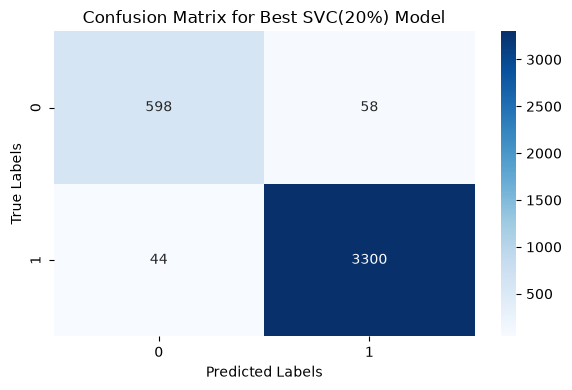

In [124]:
grid_rf_20_predictions = grid.predict(X_rf_20_test)

cmG_rf_20 = confusion_matrix(y_rf_20_test, grid_rf_20_predictions)


plt.figure(figsize = (6,4))
sns.heatmap(cmG_rf_20, annot = True, fmt =  'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for Best SVC(20%) Model')
plt.tight_layout()
plt.show()   

In [125]:
# Print classification report
print("\nClassification Report:\n")
print(classification_report(y_rf_20_test, grid_rf_20_predictions))


Classification Report:

              precision    recall  f1-score   support

           0       0.93      0.91      0.92       656
           1       0.98      0.99      0.98      3344

    accuracy                           0.97      4000
   macro avg       0.96      0.95      0.95      4000
weighted avg       0.97      0.97      0.97      4000



# Random Forest (test size 15%)

In [126]:
X_rf_15=df.drop(columns=['Outcome'])
y_rf_15=df['Outcome']

In [127]:
X_rf_15_train, X_rf_15_test,y_rf_15_train, y_rf_15_test = train_test_split(X_rf_15,y_rf_15, test_size=0.15, random_state=0)
X_rf_15_train.shape, X_rf_15_test.shape,y_rf_15_train.shape, y_rf_15_test.shape

((17000, 14), (3000, 14), (17000,), (3000,))

In [128]:
clf_rf_15=RandomForestClassifier(class_weight='balanced',criterion='gini',max_depth=4,random_state=0)
#이제 decisiontree 하는데 뭐를 criterion 잡고 max depth 설정
clf_rf_15=clf_rf_15.fit(X_rf_15_train,y_rf_15_train)
y_rf_15_predict=clf_rf_15.predict(X_rf_15_test)

In [129]:
results = pd.DataFrame({
    "y_rf_15_test (True)": y_rf_15_test.reset_index(drop=True),  # reset index for alignment
    "y_rf_15_predict (Predicted)": y_rf_15_predict
})

# Show first 20 rows for a quick view
print(results.head(20))

    y_rf_15_test (True)  y_rf_15_predict (Predicted)
0                     1                            1
1                     1                            1
2                     1                            1
3                     0                            0
4                     1                            0
5                     1                            1
6                     1                            1
7                     1                            1
8                     1                            1
9                     1                            1
10                    1                            0
11                    0                            0
12                    1                            1
13                    1                            1
14                    1                            1
15                    1                            1
16                    1                            1
17                    1                       

In [131]:
# If you also want to check correctness
results["Correct?"] = results["y_rf_15_test (True)"] == results["y_rf_15_predict (Predicted)"]

print(results.head(20))

    y_rf_15_test (True)  y_rf_15_predict (Predicted)  Correct?
0                     1                            1      True
1                     1                            1      True
2                     1                            1      True
3                     0                            0      True
4                     1                            0     False
5                     1                            1      True
6                     1                            1      True
7                     1                            1      True
8                     1                            1      True
9                     1                            1      True
10                    1                            0     False
11                    0                            0      True
12                    1                            1      True
13                    1                            1      True
14                    1                            1   

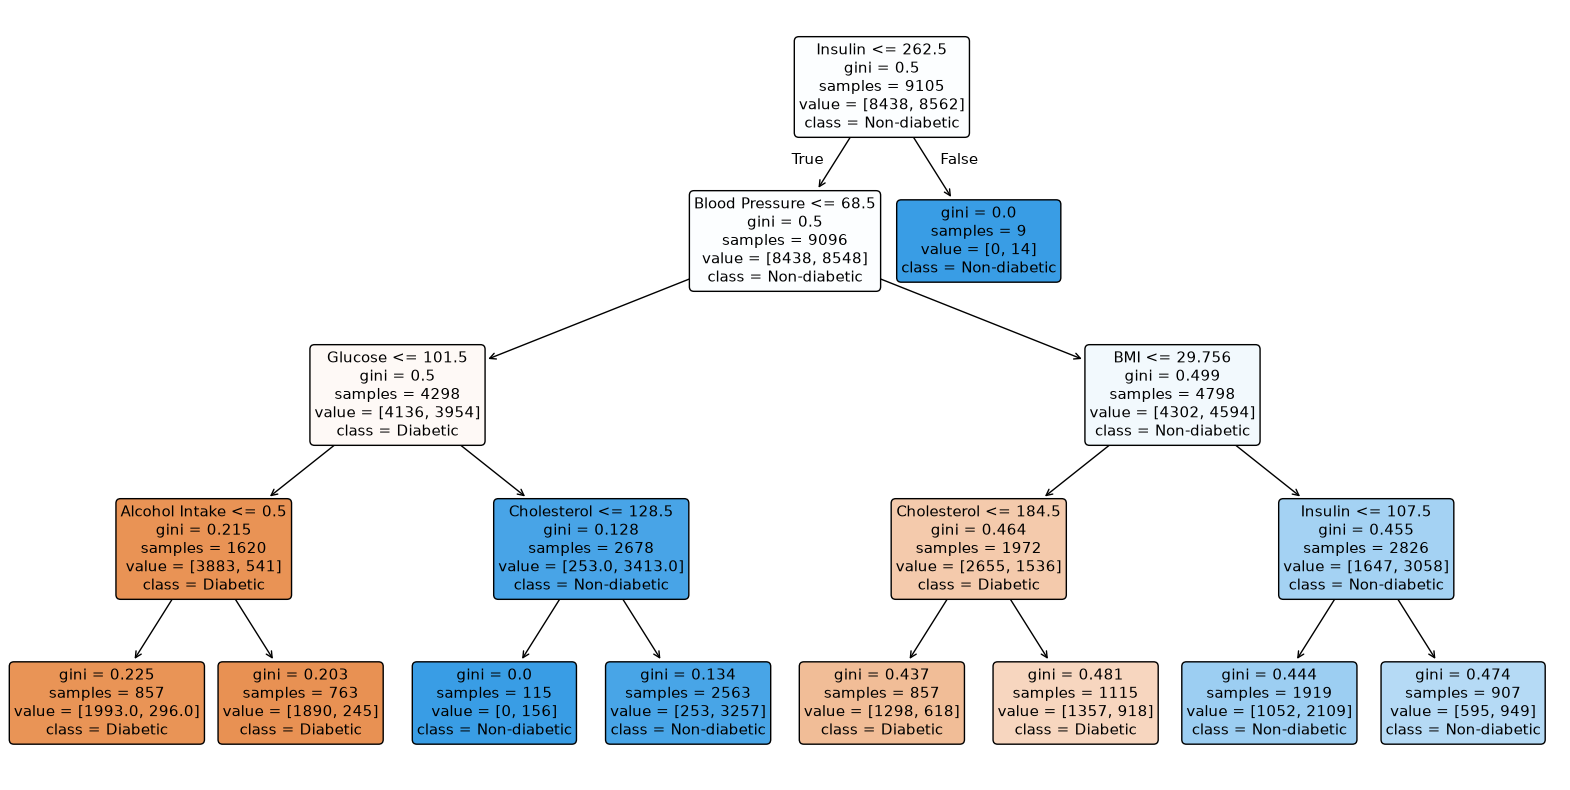

In [132]:
tree=clf_rf_15.estimators_[0]
plt.figure(figsize=(20,10))
plot_tree(tree, feature_names=X_rf_15.columns.tolist(),class_names=['Diabetic','Non-diabetic'],filled=True,rounded=True)
plt.show()

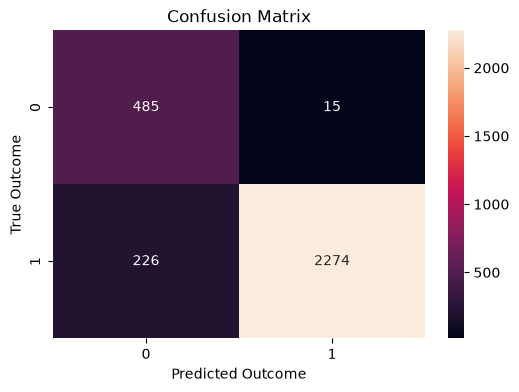

In [133]:
# Predict by using an object classifier 'clf'
y_rf_15_predict = clf_rf_15.predict(X_rf_15_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm_rf_15 = confusion_matrix(y_rf_15_test, y_rf_15_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm_rf_15, annot = True, fmt = 'd')        # 'd' stands for integer format
plt.xlabel('Predicted Outcome')
plt.ylabel('True Outcome')
plt.title('Confusion Matrix')
plt.show()

In [134]:
print(classification_report(y_rf_15_test, y_rf_15_predict))

              precision    recall  f1-score   support

           0       0.68      0.97      0.80       500
           1       0.99      0.91      0.95      2500

    accuracy                           0.92      3000
   macro avg       0.84      0.94      0.88      3000
weighted avg       0.94      0.92      0.92      3000



In [ ]:


rf_15_grid = RandomForestClassifier()
rf_15_gr_space= {'max_depth': [3,5,7,10],
    'n_estimators': [100, 200, 300, 400, 500],
    'max_features': [10, 20, 30 , 40],
    'min_samples_leaf': [1, 2, 4]}

grid=GridSearchCV(rf_15_grid, rf_15_gr_space, cv=3, scoring='accuracy', verbose=4)
model_rf_15_grid = grid.fit(X_rf_15_train, y_rf_15_train)

print("Best Parameters:", grid.best_params_)
print("Best Estimator:", grid.best_estimator_)


Fitting 3 folds for each of 240 candidates, totalling 720 fits
[CV 1/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=100;, score=0.963 total time=   0.7s
[CV 2/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=100;, score=0.963 total time=   0.7s
[CV 3/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=100;, score=0.969 total time=   0.7s
[CV 1/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=200;, score=0.966 total time=   1.6s
[CV 2/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=200;, score=0.962 total time=   1.7s
[CV 3/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=200;, score=0.968 total time=   1.8s
[CV 1/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=300;, score=0.963 total time=   2.3s
[CV 2/3] END max_depth=3, max_features=10, min_samples_leaf=1, n_estimators=300;, score=0.963 total time=   2.4s
[CV 3/3] END max_depth=3, max_fea

In [ ]:
grid_rf_15_predictions = grid.predict(X_rf_15_test)

cmG_rf_15 = confusion_matrix(y_rf_15_test, grid_rf_15_predictions)


plt.figure(figsize = (6,4))
sns.heatmap(cmG_rf_15, annot = True, fmt =  'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for Best SVC(15%) Model')
plt.tight_layout()
plt.show()   

In [ ]:
# Print classification report
print("\nClassification Report:\n")
print(classification_report(y_rf_15_test, grid_rf_15_predictions))

# random forest(test size 5%)

In [ ]:
X_rf_05=df.drop(columns=['Outcome'])
y_rf_05=df['Outcome']

In [ ]:
X_rf_05_train, X_rf_05_test,y_rf_05_train, y_rf_05_test = train_test_split(X_rf_05,y_rf_05, test_size=0.05, random_state=0)
X_rf_05_train.shape, X_rf_05_test.shape,y_rf_05_train.shape, y_rf_05_test.shape

In [ ]:
clf_rf_05=RandomForestClassifier(class_weight='balanced',criterion='gini',max_depth=4,random_state=0)
#이제 decisiontree 하는데 뭐를 criterion 잡고 max depth 설정
clf_rf_05=clf_rf_05.fit(X_rf_05_train,y_rf_05_train)
y_rf_05_predict=clf_rf_05.predict(X_rf_05_test)

In [ ]:
results = pd.DataFrame({
    "y_rf_05_test (True)": y_rf_05_test.reset_index(drop=True),  # reset index for alignment
    "y_rf_05_predict (Predicted)": y_rf_05_predict
})

# Show first 20 rows for a quick view
print(results.head(20))

In [ ]:
# If you also want to check correctness
results["Correct?"] = results["y_rf_05_test (True)"] == results["y_rf_05_predict (Predicted)"]

print(results.head(20))

In [ ]:
tree=clf_rf_05.estimators_[0] # different results as changing the number insde []
plt.figure(figsize=(20,10))
plot_tree(tree, feature_names=X_rf_05.columns.tolist(),class_names=['Diabetic','Non-diabetic'],filled=True,rounded=True)
plt.show()

In [ ]:
# Predict by using an object classifier 'clf'
y_rf_05_predict = clf_rf_05.predict(X_rf_05_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm_rf_05 = confusion_matrix(y_rf_05_test, y_rf_05_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm_rf_05, annot = True, fmt = 'd')        # 'd' stands for integer format
plt.xlabel('Predicted Outcome')
plt.ylabel('True Outcome')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
print(classification_report(y_rf_05_test, y_rf_05_predict))

In [ ]:


rf_05_grid = RandomForestClassifier()
rf_05_gr_space= {'max_depth': [3,5,7,10],
    'n_estimators': [100, 200, 300, 400, 500],
    'max_features': [10, 20, 30 , 40],
    'min_samples_leaf': [1, 2, 4]}

grid=GridSearchCV(rf_05_grid, rf_05_gr_space, cv=3, scoring='accuracy', verbose=4)
model_rf_05_grid = grid.fit(X_rf_05_train, y_rf_05_train)

print("Best Parameters:", grid.best_params_)
print("Best Estimator:", grid.best_estimator_)


In [ ]:
grid_rf_05_predictions = grid.predict(X_rf_05_test)

cmG_rf_05 = confusion_matrix(y_rf_05_test, grid_rf_05_predictions)


plt.figure(figsize = (6,4))
sns.heatmap(cmG_rf_05, annot = True, fmt =  'd', cmap = 'Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for Best SVC(05%) Model')
plt.tight_layout()
plt.show()   

In [ ]:
# Print classification report
print("\nClassification Report:\n")
print(classification_report(y_rf_05_test, grid_rf_05_predictions))

In [ ]:


# Create an initialise an object 'nvclassifier' by calling a method 'GaussianNB()'
nvclassifier = RandomForestClassifier()

# Calculate the score using cross validation method
cross_val_score = cross_val_score(nvclassifier, X, y, scoring = 'accuracy', cv = 10).mean() #cv=10-Fold Cross Validation(10겹 교차 검증)
#choose one as testing, and the others for training. for second, choose another one as testing and the others for training. and repeat it for 10 times.

print(cross_val_score) #데이터를 10개 그룹으로 나누고 10번의 교차검증을 마치고 난 후(1번째 - 1번이 평가 2-10까지 학습. 2번째 - 2번이 평가 1,3-10이 학습 ...), 10번의 정확도를 평균을 낸다.